In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
excel_fs = ['CMM 10 tulipes AAR3-33 tournées_analysis',
'CMM 30 tulipes brutes_analysis2',
'CMM batch O finished parts',
'CMM N1-N30 finished part Batch N']

In [7]:
excel_f = excel_fs[0]
n_of_results = 10
data = pd.read_excel(f'../{excel_f}.xlsx', skiprows=7)
data

,Unnamed: 0,LOH_ENG,CMMID,111793-01 _Act,111793-02 _Act,111793-03 _Act,111793-04 _Act,111793-05 _Act,111793-06 _Act,111793-07 _Act,...,111793-01 _Dev,111793-02 _Dev,111793-03 _Dev,111793-04 _Dev,111793-05 _Dev,111793-06 _Dev,111793-07 _Dev,111793-08 _Dev,111793-09 _Dev,111793-10 _Dev
0,NaN,NaN,NOTE1610b,0.0607,0.0336,0.0453,0.0240,0.0654,0.0452,0.0279,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,SDA1_M3_to_M2,0.0002,0.0074,0.0033,0.0123,0.0028,0.0032,0.0021,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,SDB1_M2_to_M1,0.0102,0.0296,0.0140,0.0240,0.0275,0.0165,0.0279,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,SDB2_M3_to_M2,0.0075,0.0154,0.0345,0.0017,0.0089,0.0185,0.0115,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,SDC1_M3_to_M2,0.0087,0.0021,0.0304,0.0047,0.0067,0.0086,0.0046,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
302,NaN,External Diameter,ED,89.9781,89.9816,89.9766,89.9844,89.9825,89.9568,89.9742,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
303,NaN,Outer face Distance A,OFA,40.3636,40.3742,40.3792,40.3666,40.3718,40.3535,40.3805,...,NaN,NaN,0.0042,NaN,NaN,NaN,0.0055,NaN,NaN,NaN
304,NaN,Outer face Distance B,OFB,40.3752,40.3791,40.3675,40.3751,40.3705,40.3513,40.3723,...,0.0002,0.0041,NaN,0.0001,NaN,NaN,NaN,NaN,0.0052,NaN
305,NaN,Outer face Distance C,OFC,40.3591,40.3870,40.3468,40.3715,40.3771,40.3603,40.3446,...,NaN,0.0120,NaN,NaN,0.0021,NaN,NaN,NaN,NaN,NaN


In [5]:
data_f = data[data.iloc[:, 2].astype(str).str.match(r'SD(A|B|C)\dM', na=False)]
data_f = data_f.dropna(axis=1)
data_f

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
241,Shoulder Distance Track A1 at ME1,SDA1ME1_Y,8.1548,8.1859,8.1602,8.1783,8.1674,8.1563,8.162,8.1516,8.1641,8.1642,8.16,0.05,-0.05,8.21,8.11
242,Shoulder Distance Track A2 at ME1,SDA2ME1_Y,8.154,8.1477,8.1537,8.1567,8.1396,8.1582,8.1363,8.15,8.138,8.1324,8.16,0.05,-0.05,8.21,8.11
243,Shoulder Distance Track B1 at ME1,SDB1ME1_Y,8.145,8.1865,8.149,8.1622,8.1682,8.1758,8.1428,8.1392,8.1545,8.1478,8.16,0.05,-0.05,8.21,8.11
244,Shoulder Distance Track B2 at ME1,SDB2ME1_Y,8.1776,8.1328,8.1576,8.1487,8.1316,8.1269,8.1693,8.1529,8.1527,8.1668,8.16,0.05,-0.05,8.21,8.11
245,Shoulder Distance Track C1 at ME1,SDC1ME1_Y,8.1662,8.1972,8.17,8.1596,8.2092,8.1824,8.1694,8.1505,8.1502,8.1758,8.16,0.05,-0.05,8.21,8.11
246,Shoulder Distance Track C2 at ME1,SDC2ME1_Y,8.1579,8.1509,8.1408,8.1526,8.1391,8.1423,8.1426,8.1527,8.1551,8.1312,8.16,0.05,-0.05,8.21,8.11
247,Shoulder Distance Track A1 at ME2,SDA1ME2_Y,8.1449,8.1605,8.1462,8.1575,8.1515,8.1415,8.1398,8.1337,8.1558,8.1405,8.16,0.05,-0.05,8.21,8.11
248,Shoulder Distance Track A2 at ME2,SDA2ME2_Y,8.1105,8.1111,8.1121,8.1358,8.1183,8.1321,8.1188,8.1299,8.1225,8.1229,8.16,0.05,-0.05,8.21,8.11
249,Shoulder Distance Track B1 at ME2,SDB1ME2_Y,8.1348,8.1569,8.135,8.1383,8.1407,8.1593,8.115,8.1162,8.1362,8.125,8.16,0.05,-0.05,8.21,8.11
250,Shoulder Distance Track B2 at ME2,SDB2ME2_Y,8.1458,8.0955,8.1605,8.1274,8.108,8.1191,8.1489,8.1315,8.1417,8.1455,8.16,0.05,-0.05,8.21,8.11


In [6]:
pop = data[data.iloc[:, 2].astype(str).str.match(r'SDA1ME', na=False)].dropna(axis=1)
pop

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
241,Shoulder Distance Track A1 at ME1,SDA1ME1_Y,8.1548,8.1859,8.1602,8.1783,8.1674,8.1563,8.162,8.1516,8.1641,8.1642,8.16,0.05,-0.05,8.21,8.11
247,Shoulder Distance Track A1 at ME2,SDA1ME2_Y,8.1449,8.1605,8.1462,8.1575,8.1515,8.1415,8.1398,8.1337,8.1558,8.1405,8.16,0.05,-0.05,8.21,8.11
253,Shoulder Distance Track A1 at ME3,SDA1ME3_Y,8.145,8.1532,8.1429,8.1452,8.1487,8.1383,8.1377,8.132,8.1399,8.1256,8.16,0.05,-0.05,8.21,8.11
259,Shoulder Distance Track A1 at ME4,SDA1ME4_Y,8.0844,8.1434,8.1351,8.1306,8.1381,8.1241,8.126,8.1201,8.1339,8.127,8.16,0.05,-0.05,8.21,8.11
265,Shoulder Distance Track A1 at ME5,SDA1ME5_Y,8.1383,8.1398,8.1375,8.1207,8.1301,8.1244,8.1242,8.1093,8.1308,8.1265,8.16,0.05,-0.05,8.21,8.11


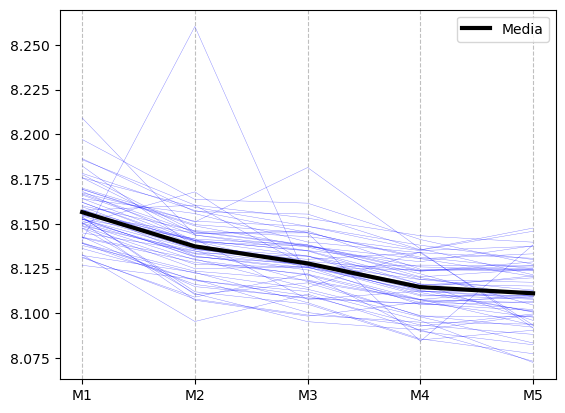

In [13]:
f, ax = plt.subplots()

all_curves = []
x = range(1, 6)
labels = ['M1', 'M2', 'M3', 'M4', 'M5']


pistas = ['A1', 'A2', 'B1', 'B2', 'C1', 'C2']
for pista in pistas:

    pop = data[data.iloc[:, 2].astype(str).str.match(f'SD{pista}ME', na=False)].dropna(axis=1)
    for i in range(2, 2+10):
        y = pop.iloc[:, i].values

        ax.plot(range(1, 6), y, lw=0.3, color='b', alpha=0.5)

        all_curves.append(y)

for xpos in x:
     ax.axvline(xpos,color='gray',linestyle='--',lw=0.8,alpha=0.5,zorder=0)   

mean_curve = np.mean(np.vstack(all_curves), axis=0)

ax.plot(range(1, 6),mean_curve,color='k',lw=3,label='Media')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
plt.show()
